# MATH1604 Individual Project: Evolutionary Optimisation

## 1. Introduction

Name: Zikril Hakim Bin Shahrol Hanizam

SID: 201963331

This project investigates a simple evolutionary optimisation model. The aim is to evolve random text sequences towards a fixed target sequence using mutation and selection. The target sequence is taken from Shakespeare Sonnet 31, since my student number ends in 31.

The model uses Hamming distance to measure how different each candidate string is from the target. I investigate how the mutation probability p and population size N affect the number of generations needed to reach the target.

In [1]:
import random
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

alphabet = string.ascii_lowercase + " "

master = "thy bosom is endeared with all hearts which i by lacking have supposed dead"
L = len(master)

print("Target sequence:")
print(master)
print("Length:", L)

Target sequence:
thy bosom is endeared with all hearts which i by lacking have supposed dead
Length: 75


## 2. Hamming Distance

Hamming distance counts the number of positions where two strings of equal length are different. In this model, it acts as the objective function: a smaller distance means the candidate sequence is closer to the master sequence.

In [2]:
def hamming_distance(s1, s2):
    if len(s1) != len(s2):
        raise ValueError("Strings must have equal length")
    return sum(c1 != c2 for c1, c2 in zip(s1, s2))

# Test
print(hamming_distance("data", "date"))
print(hamming_distance(master, master))

1
0


## 3. Model Functions

The model begins by creating random strings of the same length as the master sequence. Mutation then copies a sequence, but each character has probability p of changing into another random character.

In [3]:
def random_sequence(L):
    return "".join(random.choice(alphabet) for _ in range(L))

def mutate_sequence(seq, p):
    new_seq = []
    for ch in seq:
        if random.random() < p:
            choices = [c for c in alphabet if c != ch]
            new_seq.append(random.choice(choices))
        else:
            new_seq.append(ch)
    return "".join(new_seq)

def best_random_sequence(master, N):
    candidates = [random_sequence(len(master)) for _ in range(N)]
    return min(candidates, key=lambda s: hamming_distance(s, master))

## 4. Stopping Condition

The brief says the model can stop when the target is recovered exactly, or when the sequence has only one or two acceptable remaining errors. For simplicity and clarity, I first use exact recovery as the main stopping condition.

In [4]:
def stopping_condition(seq, master):
    return hamming_distance(seq, master) == 0

## 5. Evolutionary Algorithm

At each generation, the current best sequence produces N offspring. Each offspring is a mutated copy. If the best offspring has a smaller Hamming distance than the current sequence, it replaces the current sequence. Otherwise, the current sequence is kept.

In [5]:
def evolve(master, N=10, p=0.1, max_generations=5000):
    current = best_random_sequence(master, N)
    history = [hamming_distance(current, master)]

    for g in range(1, max_generations + 1):
        offspring = [mutate_sequence(current, p) for _ in range(N)]
        best_child = min(offspring, key=lambda s: hamming_distance(s, master))

        if hamming_distance(best_child, master) < hamming_distance(current, master):
            current = best_child

        history.append(hamming_distance(current, master))

        if stopping_condition(current, master):
            return current, g, True, history

    return current, max_generations, False, history

## 6. Example Run

First, I run the model once to check that the distance generally decreases over time.

Final sequence:
thy bosom is endeared with all hearts which i by lacking have supposed dead
Final distance: 0
Generations: 3497
Success: True


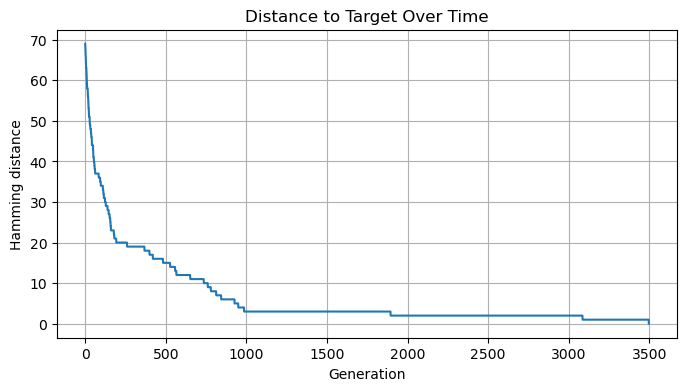

In [6]:
result = evolve(master, N=20, p=0.05, max_generations=10000)

final_seq, generations, success, history = result

print("Final sequence:")
print(final_seq)
print("Final distance:", hamming_distance(final_seq, master))
print("Generations:", generations)
print("Success:", success)

plt.figure(figsize=(8, 4))
plt.plot(history)
plt.xlabel("Generation")
plt.ylabel("Hamming distance")
plt.title("Distance to Target Over Time")
plt.grid(True)
plt.show()

## 7. Experiment 1: Effect of Mutation Probability

I investigate how the mutation probability p affects convergence. If p is too small, the algorithm may improve slowly because there is little variation. If p is too large, good partial solutions may be disrupted too often.

,p,mean_generations,success_rate,mean_final_distance
0,0.01,1151.6,1.0,0.0
1,0.03,1214.4,1.0,0.0
2,0.05,2982.0,0.2,1.0
3,0.10,3000.0,0.0,14.4
4,0.20,3000.0,0.0,32.4


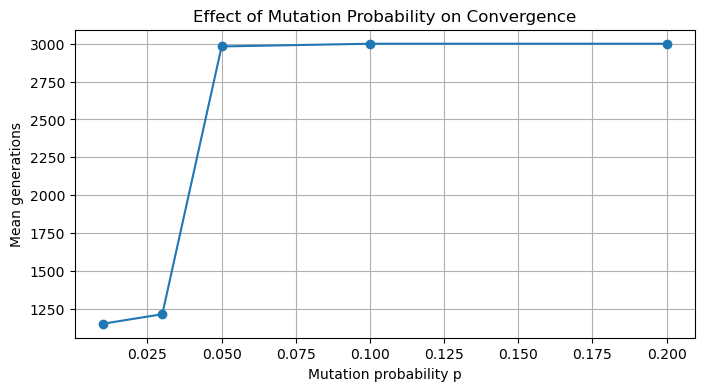

In [7]:
def run_trials(master, N, p, trials=5, max_generations=3000):
    results = []

    for trial in range(trials):
        final_seq, generations, success, history = evolve(
            master, N=N, p=p, max_generations=max_generations
        )

        results.append({
            "N": N,
            "p": p,
            "trial": trial + 1,
            "generations": generations,
            "success": success,
            "final_distance": hamming_distance(final_seq, master)
        })

    return pd.DataFrame(results)


p_values = [0.01, 0.03, 0.05, 0.1, 0.2]
all_p_results = []

for p in p_values:
    df = run_trials(master, N=20, p=p, trials=5, max_generations=3000)
    all_p_results.append(df)

p_results = pd.concat(all_p_results, ignore_index=True)

p_summary = p_results.groupby("p").agg(
    mean_generations=("generations", "mean"),
    success_rate=("success", "mean"),
    mean_final_distance=("final_distance", "mean")
).reset_index()

display(p_summary)

plt.figure(figsize=(8, 4))
plt.plot(p_summary["p"], p_summary["mean_generations"], marker="o")
plt.xlabel("Mutation probability p")
plt.ylabel("Mean generations")
plt.title("Effect of Mutation Probability on Convergence")
plt.grid(True)
plt.show()

## 8. Experiment 2: Effect of Population Size

Next, I investigate population size N. A larger N gives the algorithm more offspring to choose from each generation, so it may improve faster. However, it also requires more computation.

,N,mean_generations,success_rate,mean_final_distance
0,5,3000.0,0.0,8.8
1,10,3000.0,0.0,3.0
2,20,2437.2,0.8,0.2
3,40,1686.2,1.0,0.0


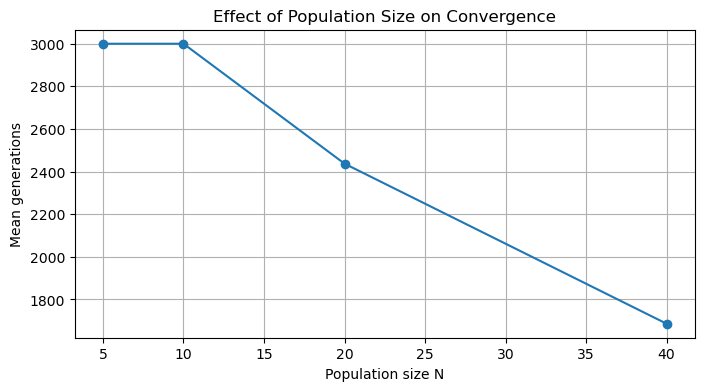

In [8]:
N_values = [5, 10, 20, 40]
all_N_results = []

for N in N_values:
    df = run_trials(master, N=N, p=0.05, trials=5, max_generations=3000)
    all_N_results.append(df)

N_results = pd.concat(all_N_results, ignore_index=True)

N_summary = N_results.groupby("N").agg(
    mean_generations=("generations", "mean"),
    success_rate=("success", "mean"),
    mean_final_distance=("final_distance", "mean")
).reset_index()

display(N_summary)

plt.figure(figsize=(8, 4))
plt.plot(N_summary["N"], N_summary["mean_generations"], marker="o")
plt.xlabel("Population size N")
plt.ylabel("Mean generations")
plt.title("Effect of Population Size on Convergence")
plt.grid(True)
plt.show()

## 9. Discussion

The results show that the behaviour of the evolutionary model depends strongly on parameter choices. Very small mutation probabilities can make progress slow because the algorithm explores only a small number of changes. Very large mutation probabilities can also be inefficient because they may disrupt characters that are already correct.

The population size also affects convergence. Larger values of N usually increase the chance that at least one offspring improves on the parent sequence. However, larger populations are computationally more expensive because more candidate sequences must be evaluated in each generation.

This model is a simplified example of optimisation. Similar ideas appear in data science when algorithms search for good solutions, such as model parameters, feature selections, or approximate solutions in noisy systems.

## 10. Limitations and Conclusion

This model is useful because it clearly shows the role of mutation, selection, and distance-based optimisation. However, it is also simplified. It only keeps improvements, uses a fixed mutation probability, and treats every character independently. Real optimisation problems often involve more complex search spaces and may require more advanced strategies.

Overall, the investigation suggests that evolutionary optimisation works best when there is a balance between exploration and preservation. Mutation must be large enough to create useful variation, but not so large that it destroys progress.